# Lab 10: Developing machine learning models using Keras.
- In this lab you will understand the basics of using Keras deep learning framework.
- You will use existing datasets and learn how to preprocess it.
- Use prepared dataset to train model.
- Use the trained model to evaluate against new images.
- Saving and loading models
- Finally Understanding the benefits on Transfer learning.


# General instructions for the lab
Before jumping in, it is important to understand the `datset` and its `labels`.

    1. Normalize the dataset, change the labels and split it for training and validation/test.
    2. Building a custom CNN or using an existing architecture.
    3. Selecting appropriate hyperparameters.
    4. Training the model till best results
    5. Using the model for predictions.

#### You can use GPU for an improved training speed (if available).
- On google colab: https://colab.research.google.com

Goto Runtime -> Change Runtime Type -> Change Hardware Accelerator from None to GPU.


# Keras
In this lab we will use focus on Keras, which is an open-source library written in Python language. It uses tensforflow on the backend and provides high level APIs. Keras is a lot simpler compared to tensorflow and other deep learning libraries.

Note: You can choose tensforflow and pytorch for customized implementations.

In [27]:
# !pip install tensorflow
# !pip install utils

In [28]:
# Import necessary libraries numpy, mataplotlib, sklearn, random, etc
import tensorflow as tf
from tensorflow import keras
import numpy as np
import matplotlib.pyplot as plt
import random

np.random.seed(42)
random.seed(42)
keras.utils.set_random_seed(42)


# DATASET (MNIST)

The MNIST database (Modified National Institute of Standards and Technology database) is a large collection of handwritten digits. It has a training set of 60,000 examples, and a test set of 10,000 examples. The digits have been size-normalized and centered in a fixed-size image.

MNIST has ten classes (0-9) corresponding to the 10 digits.

The data is stored in a very simple file format designed for storing vectors and multidimensional matrices.

[Image Ref: https://scientistcafe.com/ids/images/MnistExamples.png]

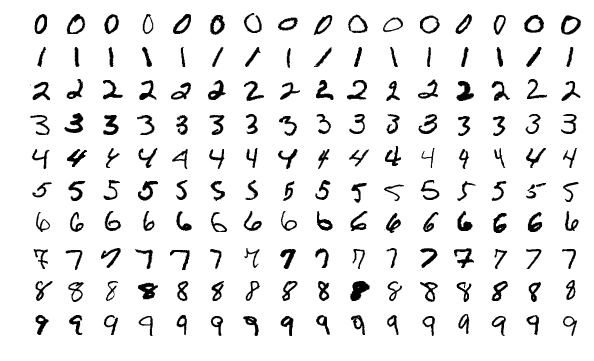

# 1. Exploring Dataset

### 1.1 Load dataset into training and test splits

In [29]:
# Getting data set and understanding how many datapoints it have.
# Keras provided load_data() method to get dataset in splits.
from keras.datasets import mnist # could be also other database source like cifar10, cifar1000, fashion_mnist
(X_train, y_train), (X_test, y_test) = mnist.load_data()
print("Training: {} | {}".format(X_train.shape, y_train.shape))
print("Test: {} | {}".format(X_test.shape, y_test.shape))
print(f"Xmin: {X_train.min()}, \tXmax: {X_train.max()}")


Training: (60000, 28, 28) | (60000,)
Test: (10000, 28, 28) | (10000,)
Xmin: 0, 	Xmax: 255


### 1.2 Normalize training and test features
Normalization improves training performs helps to reduce the digits size during the multiplication and addition operations.
</br>Images are normally 0-255 so we can normalize them to 0-1.
Note: Convert the pixel values by diving with 255 but before convert the pixel values to float32 (Remember: astype())

In [30]:
# Normalize the feature vectors (from RGB scale 0-255 to 0-1)
x_train = X_train.astype('float32') / 255
x_test = X_test.astype('float32') / 255
print(f"Xmin: {x_train.min()}, \tXmax: {x_train.max()}")

Xmin: 0.0, 	Xmax: 1.0


### 1.3 Visualization

In [31]:
# Define a dictionary to store lettered labels for each digit
labels = {0: "zero",
        1: "one", 
        2: "two",
        3: "three",        
        4: "four",
        5: "five",       
        6: "six",
        7: "seven",       
        8: "eight",
        9:  "nine"
 }

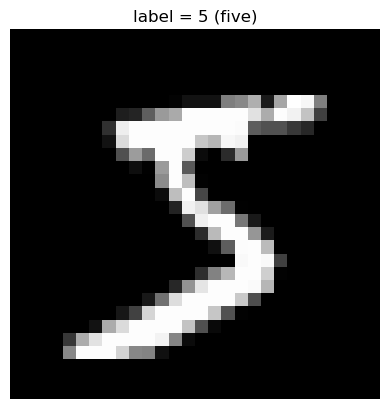

In [32]:
# Plot to visualize one image sample
plt.imshow(x_train[0], cmap='gray')
plt.title(f"label = {y_train[0]} ({labels[y_train[0]]})")
plt.axis('off')
plt.show()

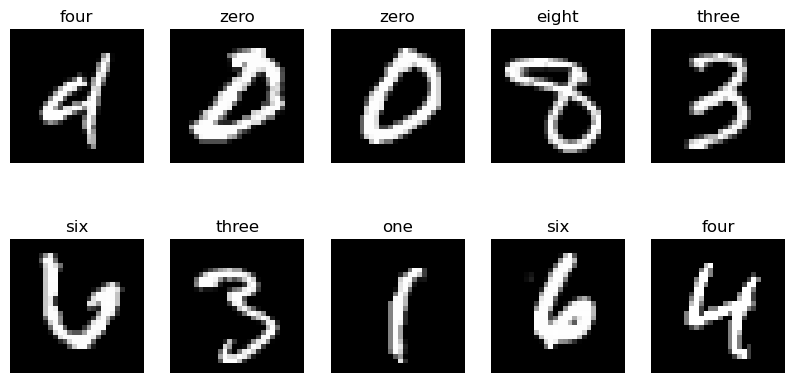

In [33]:
# Select 10 random samples from the training dataset, 
# plot their images, and show the corresponding labels
samples = np.random.randint(low=0, high=len(X_train)-1, size=10)

plt.figure(figsize=(10, 5))
for i in range(10):
    ax = plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[samples][i], cmap="gray")
    plt.title(labels[y_train[samples][i]])
    plt.axis("off")

### 1.4 Transforming labels into one-hot vectors
If you have text labels they need to converted into the numbers first. We can’t just give the categorical data to the machine for processing. So, we need to do some steps to make the data more processable for the machine.

One-hot encoding provides label in vector form of 0,1. It helps to do better predictions.
One-hot is a group of bits among which the legal combinations of values are only those with a single high bit and all the others low.

(Hint from kera.utils use np_utils and to_categorical)

**EXAMPLE**:

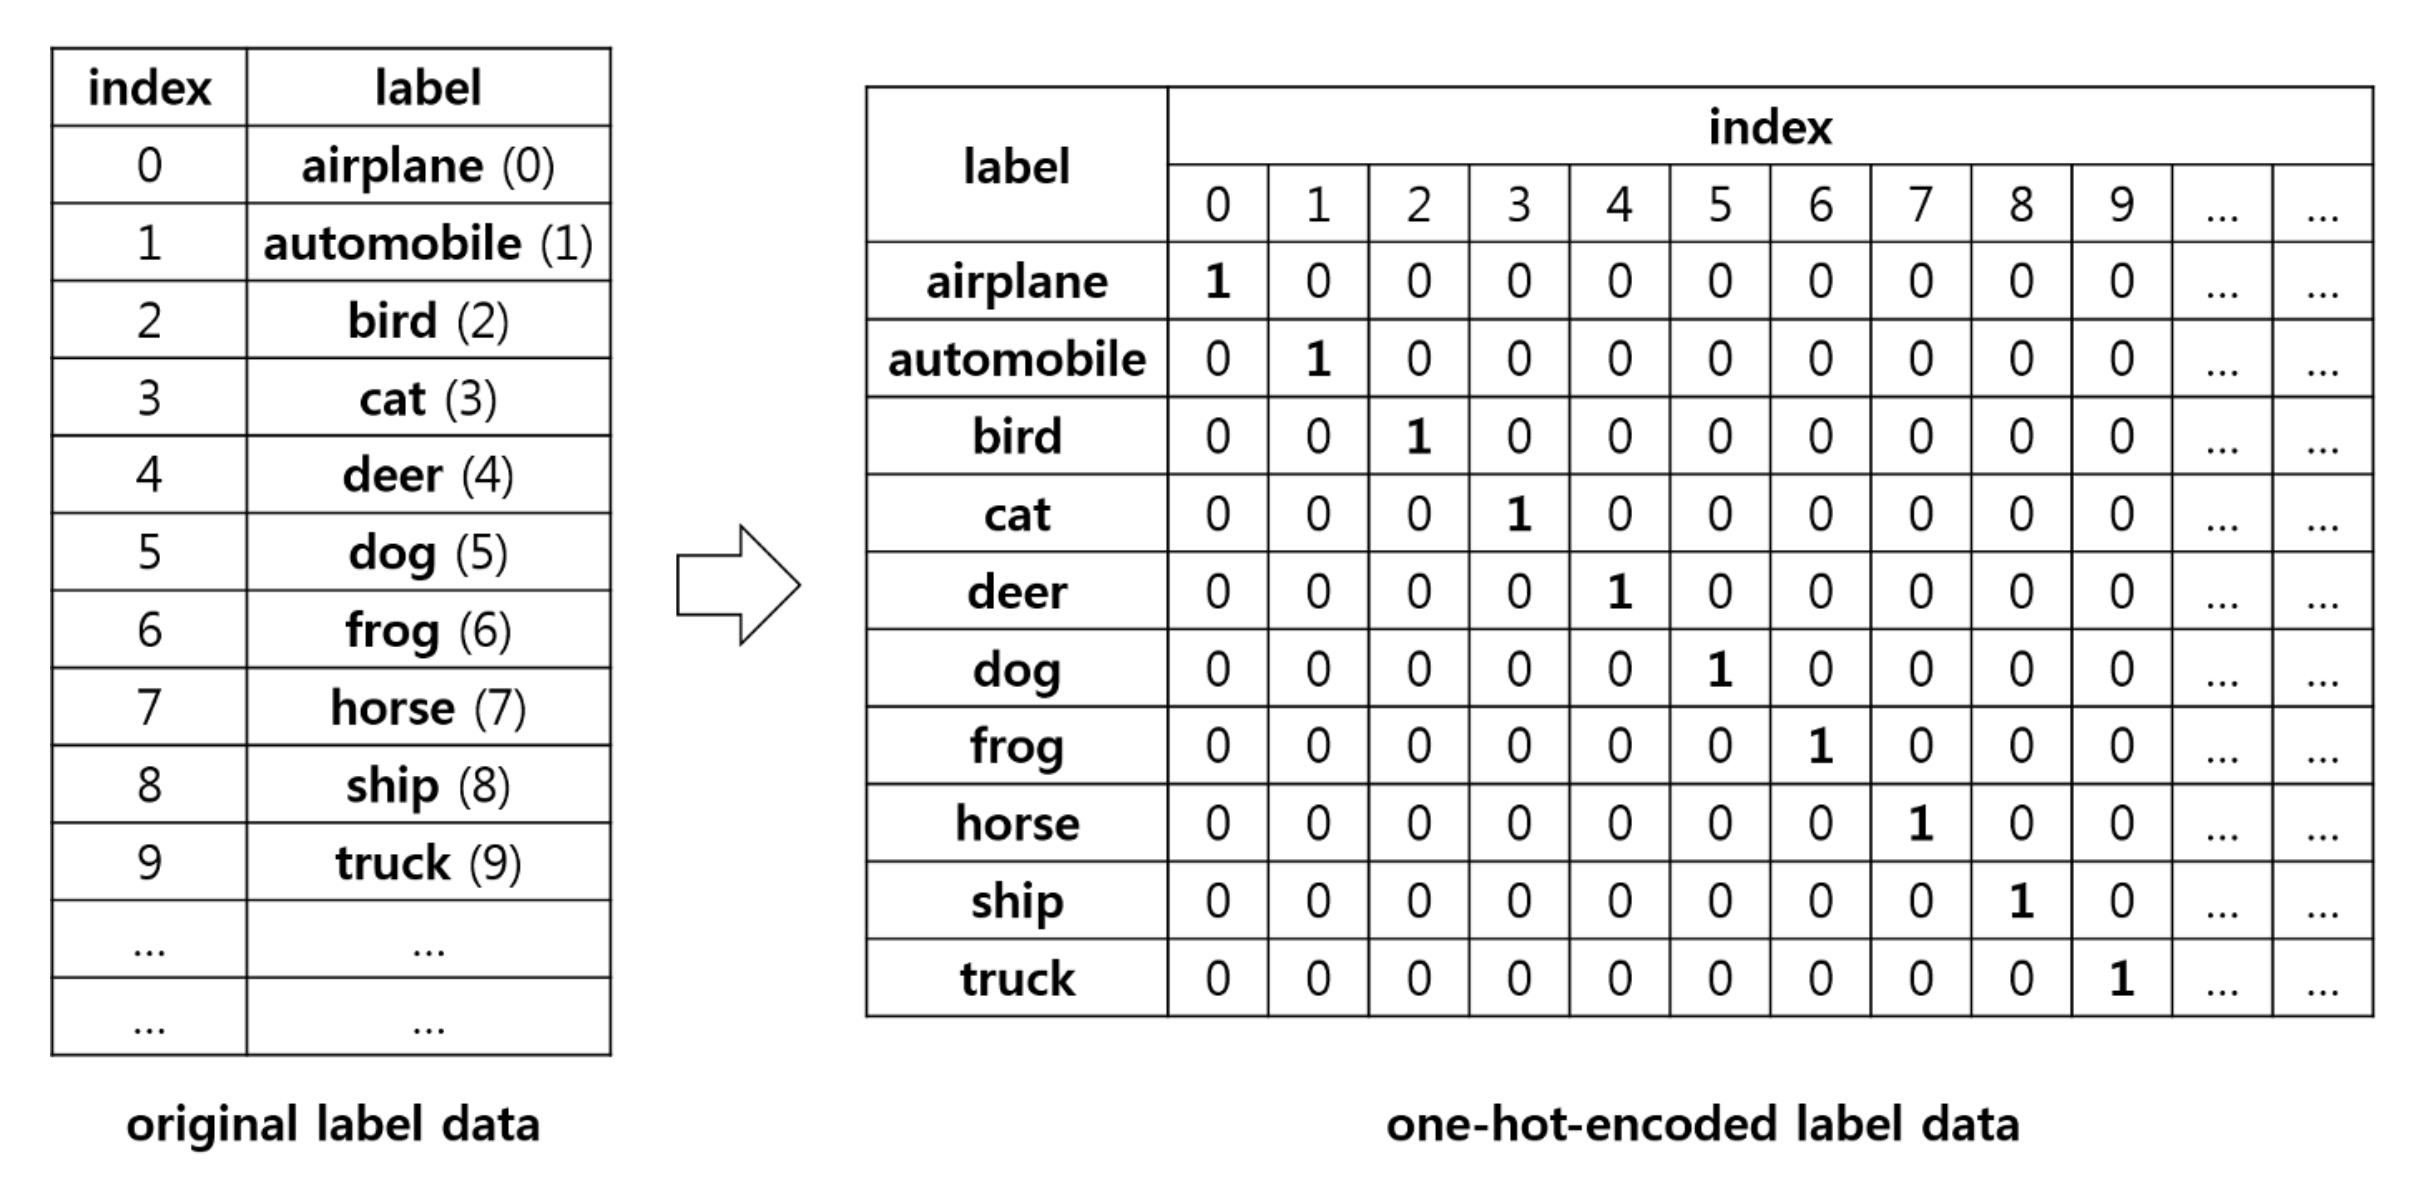

In [34]:
#from keras.utils.np_utils  import to_categorical
from tensorflow.keras.utils  import to_categorical
y_train_one_hot = to_categorical(y_train, num_classes=None)
y_test_one_hot = to_categorical(y_test, num_classes=None)
print(f"original labels \n {y_train[:3]}")
print(f"one-hot labels \n {y_train_one_hot[:3]}")
print(f"Shape of encoded labels: {y_train.shape}")

original labels 
 [5 0 4]
one-hot labels 
 [[0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]]
Shape of encoded labels: (60000,)


Now the labels are converted into binary matrices of width 10 (similar to the total classes)



# 2. Building a CNN using an existing architecture.

### 2.1 Loading State-of-the-art MobileNet model

You can use sequential from keras.models to pack a model with different layers or import available CNN architecture.
In a model, we need to define input and output layer size.

For existing architectures: https://keras.io/api/applications/

</br> for this lab we will focus on a small architecture MobileNet

[Picture Ref: https://medium.com/analytics-vidhya/image-classification-with-mobilenet-cc6fbb2cd470]

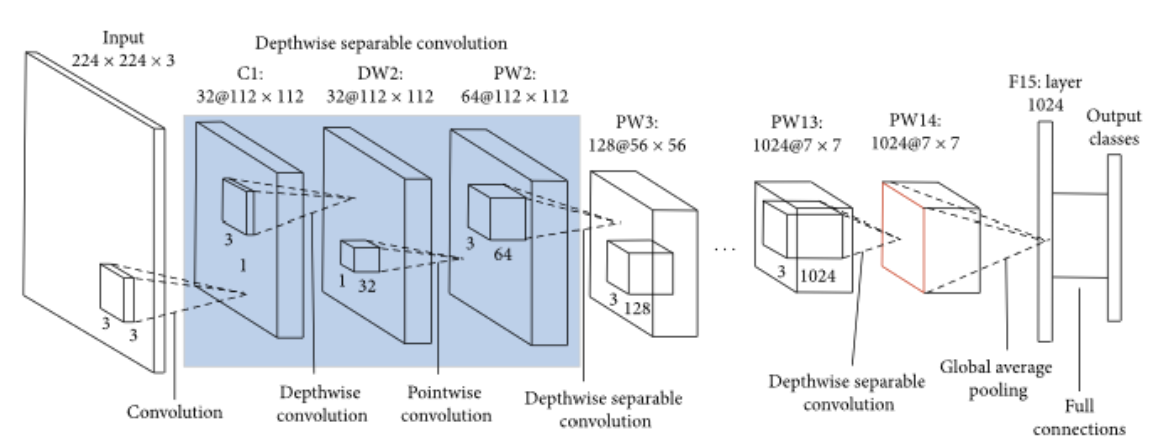

For transfer learning and finetuning you can use ImageNet

In [35]:
from tensorflow.keras.applications import MobileNet
from tensorflow.keras.layers import Input, Dense, Flatten
from tensorflow.keras.models import Model

num_classes = y_train_one_hot.shape[1] # 10

# Change include_top to false to avoid original classifier which has 1000 output, but we need 10 for MNIST
base_model = MobileNet(input_shape=(32, 32, 3), weights='imagenet', include_top=False)

# flatten output into 1D layer
x = Flatten()(base_model.output)  
# Add a dense layer with softmax activation to obtain a probability distribution as output                  
x = Dense(num_classes, activation='softmax')(x)     

# Create a model instance
model = Model(inputs=base_model.input, outputs=x)

# Freeze all but the last 6 layers for training [permits Transfer learning]
for layer in model.layers[:-6]:
    layer.trainable = False

model.summary()

Model: "model_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_3 (InputLayer)        [(None, 32, 32, 3)]       0         
                                                                 
 conv1 (Conv2D)              (None, 16, 16, 32)        864       
                                                                 
 conv1_bn (BatchNormalizati  (None, 16, 16, 32)        128       
 on)                                                             
                                                                 
 conv1_relu (ReLU)           (None, 16, 16, 32)        0         
                                                                 
 conv_dw_1 (DepthwiseConv2D  (None, 16, 16, 32)        288       
 )                                                               
                                                                 
 conv_dw_1_bn (BatchNormali  (None, 16, 16, 32)        128 

 Since the MobileNet imposes an input dimension of (32x32x3), but our input data loaded from MNIST are features of dimension (28x28)
 we need to adjust the input feature vectors to have conforming sizes, by `padding` and `stacking`.

In [36]:
# OPTION 1
# (X_train, y_train), (X_test, y_test) = mnist.load_data()

# Reshape the images to add extra dimension  (60000, 28, 28, 1)
X_train_reshaped = np.reshape(X_train, (60000, 28, 28, 1))
X_test_reshaped = np.reshape(X_test, (10000, 28, 28, 1))

# Add padding to the images to obtain (60000, 32, 32, 1)
X_train_padded = np.pad(X_train_reshaped, ((0, 0), (2, 2), (2, 2), (0, 0)), mode='constant')
X_test_padded = np.pad(X_test_reshaped, ((0, 0), (2, 2), (2, 2), (0, 0)), mode='constant')

# Stack padded data into 3 channels to obtain (60000, 32, 32, 3)
x_train = np.repeat(X_train_padded, 3, axis=-1)
x_test = np.repeat(X_test_padded, 3, axis=-1)
print(f'Input data shape resized to {x_train.shape}')

Input data shape resized to (60000, 32, 32, 3)


### 2.2 Use custom model (ALTERNATIVE)
It is also possible to create a custom neural network model that can take 28x28 Grayscale image as input. Which means we do not need to do padding, or increase channels to 28x28x3 JPEG. The pretrained model however has the advantage in that it offers possibility for transfer learning.

In [37]:
# OPTION 2: Custom Model

# model = keras.Sequential([
#    keras.layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
#    keras.layers.MaxPooling2D((2, 2)),
#    keras.layers.Flatten(),
#    keras.layers.Dense(10, activation='softmax')
#])

# model.summary()

In [38]:
# Alternative solution of custom model
# from keras.models import Sequential
# from keras.layers import Dense,Dropout,Flatten,Conv2D,MaxPooling2D

# model = sequential()
# model.add(Conv2D(32, (3, 3), input_shape=(28,28,1), activation='relu', padding='same'))
# model.add(Dropout(0.2))
# model.add(Conv2D(32, (3, 3), activation='relu', padding='same'))
# model.add(MaxPooling2D(pool_size=(2, 2)))
# model.add(Conv2D(64, (3, 3), activation='relu', padding='same'))
# model.add(Dropout(0.2))
# model.add(Conv2D(64, (3, 3), activation='relu', padding='same'))
# model.add(MaxPooling2D(pool_size=(2, 2)))
# model.add(Conv2D(128, (3, 3), activation='relu', padding='same'))
# model.add(Dropout(0.2))
# model.add(Conv2D(128, (3, 3), activation='relu', padding='same'))
# model.add(MaxPooling2D(pool_size=(2, 2)))
# model.add(Flatten())
# model.add(Dropout(0.2))
# model.add(Dense(1024, activation='relu', kernel_constraint=maxnorm(3)))
# model.add(Dropout(0.2))
# model.add(Dense(512, activation='relu', kernel_constraint=maxnorm(3)))
# model.add(Dropout(0.2))
# model.add(Dense(num_classes, activation='softmax'))

# 3. Selecting appropriate hyperparameters.

Now, after creating/selecting a model with particular input and output type. We need to choose an [optimizer](https://keras.io/api/optimizers/) and a  [loss fuction](https://keras.io/api/losses/).

An optimizer is one of the two arguments required for compiling a Keras model, it shapes and molds your model into its most accurate possible form by futzing with the weights.

A loss function is an objective quantity that a model should seek to minimize during training.

In [39]:
EPOCHS = 10
learning_rate = 0.001
loss_fn = tf.keras.losses.CategoricalCrossentropy(from_logits=False) # from_logits is true when output of model is not probability but a logit(number)
optimizer = keras.optimizers.SGD(learning_rate=learning_rate)   # SGD = Stochastic Gradient Descent
#optimizer = keras.optimizers.Adam(learning_rate=learning_rate) # Alternative optimizer

Compile the model before training it. We have compile() method in keras.

In [40]:
# keras.metrics to get more evaluation metrics
# metric = tf.keras.metrics.TopKCategoricalAccuracy(k=1, name="Top-1 Accuracy")
model.compile(loss=loss_fn, optimizer=optimizer, metrics=['accuracy'])
# model.compile(loss=loss_fn, optimizer=optimizer, metrics=metric)

# 4. Training the model till best results
It is time to make the model learn from our data and validate it on hold-out set(test set in our case).
We need to select the hyperparameters: epoch and batch_size.

<b>epoch:</b> indicates the number of passes of the entire training dataset the machine learning algorithm has completed.

<b>batch_size:</b> the number of training examples utilized in one iteration

In [41]:
logs = model.fit(
    x=x_train, 
    y=y_train_one_hot, 
    epochs=EPOCHS, 
    batch_size=256,
    validation_data=(x_test, y_test_one_hot), 
)

Epoch 1/10
235/235 [==============================] - 18s 73ms/step - loss: 1.3466 - accuracy: 0.5839 - val_loss: 1.5525 - val_accuracy: 0.5358
Epoch 2/10
235/235 [==============================] - 17s 71ms/step - loss: 0.7408 - accuracy: 0.7610 - val_loss: 0.7036 - val_accuracy: 0.7806
Epoch 3/10
235/235 [==============================] - 17s 72ms/step - loss: 0.6166 - accuracy: 0.8014 - val_loss: 0.5984 - val_accuracy: 0.8148
Epoch 4/10
235/235 [==============================] - 18s 76ms/step - loss: 0.5463 - accuracy: 0.8236 - val_loss: 0.5457 - val_accuracy: 0.8291
Epoch 5/10
235/235 [==============================] - 18s 76ms/step - loss: 0.5001 - accuracy: 0.8378 - val_loss: 0.5092 - val_accuracy: 0.8382
Epoch 6/10
235/235 [==============================] - 18s 77ms/step - loss: 0.4645 - accuracy: 0.8497 - val_loss: 0.4814 - val_accuracy: 0.8474
Epoch 7/10
235/235 [==============================] - 18s 77ms/step - loss: 0.4358 - accuracy: 0.8587 - val_loss: 0.4605 - val_accuracy:

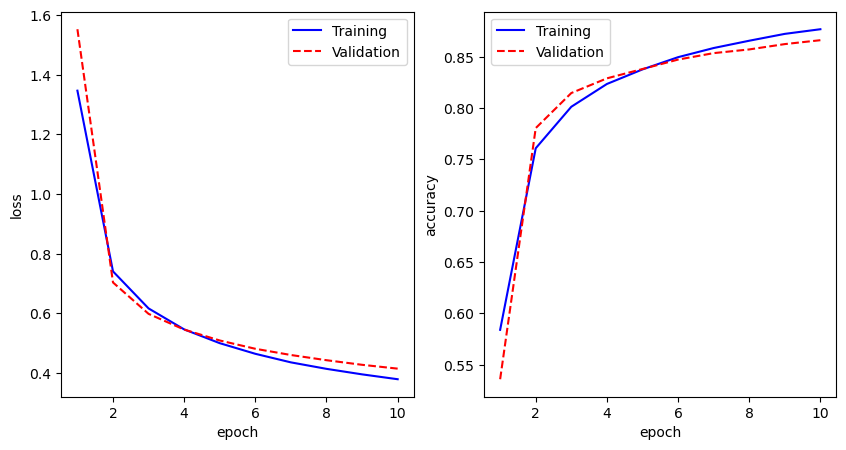

In [43]:
# Plot learning curves
x = list(range(1, EPOCHS+1))
plt.figure(figsize=(10, 5))
ax = plt.subplot(1, 2, 1)
ax.plot(x, logs.history['loss'],'b', label = "Training")
ax.plot(x, logs.history['val_loss'],'r--', label = "Validation")
ax.legend()
ax.set(xlabel='epoch', ylabel='loss')
# -------
ax = plt.subplot(1, 2, 2)
ax.plot(x, logs.history['accuracy'],'b', label = "Training")
ax.plot(x, logs.history['val_accuracy'],'r--', label = "Validation")
ax.legend()
ax.set(xlabel='epoch', ylabel='accuracy')
plt.show()

In [141]:
# Final evaluation of the model on test set.
scores = model.evaluate(x_test, y_test_one_hot, verbose=1)
print("Accuracy: %.2f%%" % (scores[1]*100))

313/313 [==============================] - 3s 11ms/step - loss: 0.4153 - accuracy: 0.8668
Accuracy: 86.68%


We chose certain values for learning rate and epochs. You can play with these hyperparamters to get higher prediction accuracy.  

# 5. Using the model for predictions.
### 5.1 Predict test examples
Use 10 random pictures from test set, get their prediction from the model, and plot them.

In [44]:
# Select 10 random samples from the test dataset, 
samples = np.random.randint(low=0, high=len(X_test)-1, size=10)
x_samples = x_test[samples]
outputs = model.predict(x_samples)
y_pred = np.argmax(outputs, axis=1)
y_pred

1/1 [==============================] - 0s 373ms/step


array([7, 8, 5, 6, 6, 2, 2, 9, 0, 9])

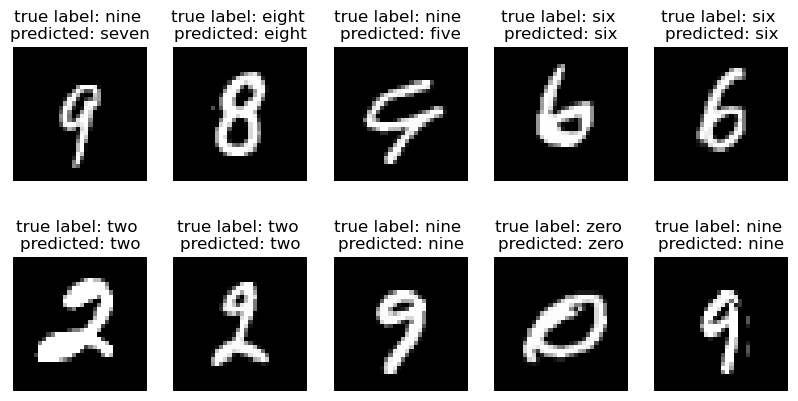

In [45]:
# plot their images, and show the corresponding true and predicted labels
plt.figure(figsize=(10, 5))
for i in range(10):
    ax = plt.subplot(2, 5, i + 1)
    ax.imshow(x_test[samples][i], cmap="gray")
    plt.title(f"true label: {labels[y_test[samples][i]]} \npredicted: {labels[y_pred[i]]}")
    plt.axis("off")

### 5.2 Unseen test data
Use the five example picture. Upload them on colab or load it from google drive if you have already connected it.


Shape of test image: (1, 32, 32, 3)


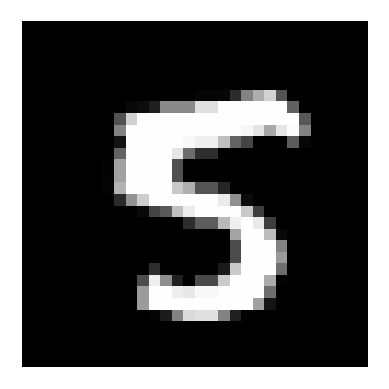

In [58]:
# External pictures
import numpy as np
from tensorflow.keras.utils import load_img, img_to_array

img_path = '../data/test-image.png'
test_image1 = load_img(img_path, target_size =(32,32))
plt.imshow(test_image1)
plt.axis('off')

# Convert test image to numpy array and adjust to match input dimension
test_image = img_to_array(test_image1)
test_image = np.expand_dims(test_image, axis=0) / 255.
print(f"Shape of test image: {test_image.shape}")

In [59]:
outputs = model.predict(test_image)
outputs

1/1 [==============================] - 0s 83ms/step


array([[6.20974170e-04, 2.57229331e-05, 9.93354013e-04, 1.97177008e-03,
        3.24643929e-06, 9.82823849e-01, 1.88448676e-03, 1.14155775e-02,
        2.27931145e-04, 3.29371796e-05]], dtype=float32)

In [60]:
# To get a position where we have highest probability
y_pred = np.argmax(outputs)
print(y_pred)
print(labels[y_pred])

5
five


### **Question:**  
Does your model predict pictures correctly? <br>What does it predict for the example image? If the prediction is incorrect, what can possibly be wrong?

Your answer: <br> The model predicts correctly on average 8 out of every 10 random samples. This is roughly consistent with the accuracy score reported.
<br> The example image when not normalized predicts 3 instead of 5. 

# 6. Save the trained model weights for future use.


In [61]:
path = '../data/my_model.h5'
model.save(path)

/Users/bawfeh78/miniconda3/envs/tf/lib/python3.10/site-packages/keras/src/engine/training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


In [62]:
#loading the saved model
from keras.models import load_model
saved_model = load_model(path)

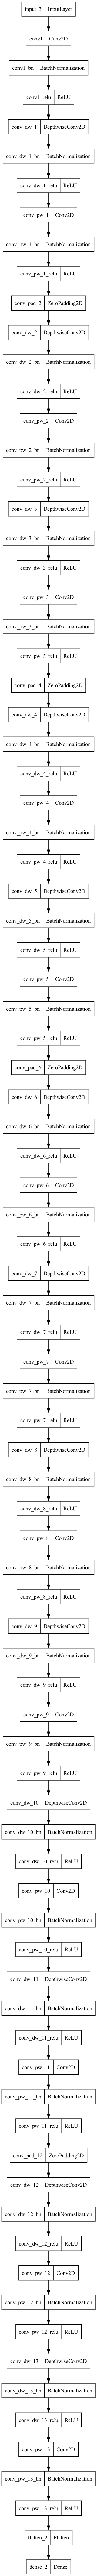

In [63]:
# Plot model summary using keras.utils method plot_model()
keras.utils.plot_model(saved_model)